## Importing data and Libraries

In [463]:
# Importing Libraries
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

df = pd.read_csv('placement.csv')


In [464]:
print(f"Shape of our dataset: {df.shape} \n\n\n")
df.head()


Shape of our dataset: (100, 4) 





,Unnamed: 0,cgpa,iq,placement
0,0,6.8,123.0,1
1,1,5.9,106.0,0
2,2,5.3,121.0,0
3,3,7.4,132.0,1
4,4,5.8,142.0,0


**Interpretation:**
Our dataset has 100 rows(Samples) and each sample has 4 features


In [465]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100 entries, 0 to 99
Data columns (total 4 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   Unnamed: 0  100 non-null    int64  
 1   cgpa        100 non-null    float64
 2   iq          100 non-null    float64
 3   placement   100 non-null    int64  
dtypes: float64(2), int64(2)
memory usage: 3.3 KB


In [466]:
df.describe()

,Unnamed: 0,cgpa,iq,placement
count,100.000000,100.000000,100.000000,100.000000
mean,49.500000,5.991000,123.580000,0.500000
std,29.011492,1.143634,39.944198,0.502519
min,0.000000,3.300000,37.000000,0.000000
25%,24.750000,5.075000,101.500000,0.000000
50%,49.500000,6.000000,127.500000,0.500000
75%,74.250000,6.900000,149.000000,1.000000
max,99.000000,8.500000,233.000000,1.000000


# 0. Preprocessing

In [467]:
# Droping the first column
df = df.iloc[:,1:]
df.head()

,cgpa,iq,placement
0,6.8,123.0,1
1,5.9,106.0,0
2,5.3,121.0,0
3,7.4,132.0,1
4,5.8,142.0,0


## Interpretation:
  * Remove the unnecessary column named 'Unnamed: 0' because it does not help us predict about Placement(Yes/No)

Text(0, 0.5, 'IQ')

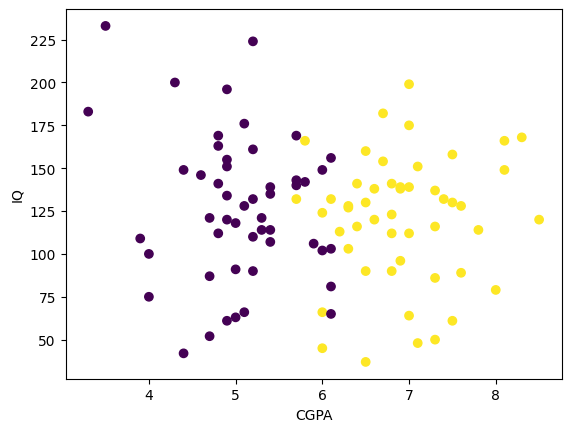

In [468]:
from matplotlib import colors
plt.scatter(df['cgpa'],df['iq'],c = df['placement'])

plt.xlabel("CGPA")
plt.ylabel("IQ")

## Interpretation:
  * The Student with higher CGPA and IQ which are selected for placement are shown with Yellow color and the other shows student who are not selected.

# 1. Extracting input and output columns

In [469]:
df.head()

,cgpa,iq,placement
0,6.8,123.0,1
1,5.9,106.0,0
2,5.3,121.0,0
3,7.4,132.0,1
4,5.8,142.0,0


In [470]:
X = df.iloc[:,0:2]
Y = df.iloc[:,-1]

In [471]:
print(f"Shape: {X.shape}")
X.head()

Shape: (100, 2)


,cgpa,iq
0,6.8,123.0
1,5.9,106.0
2,5.3,121.0
3,7.4,132.0
4,5.8,142.0


In [472]:
print(f"Shape: {Y.shape}")
Y.head(2)

Shape: (100,)


,placement
0,1
1,0


## Interpretation:
  *  X-features and Y-features are seperated succefully so we can seperate them later in Train/Test

# 2. Train Test Split

In [473]:
# Train test splitting using sklearn
from sklearn.model_selection import train_test_split
X_train, X_test, Y_train, Y_test = train_test_split(X,Y,test_size=0.2)


In [474]:
print(f"Shape of X_Train: {X_train.shape}\n\n\n")
X_train.head(10)

Shape of X_Train: (80, 2)





,cgpa,iq
48,6.6,138.0
19,5.2,132.0
66,6.9,96.0
16,5.2,224.0
33,6.0,149.0
23,4.7,87.0
90,7.3,86.0
22,4.9,120.0
58,8.0,79.0
82,6.5,37.0


In [475]:
print(f"Shape of X_Train: {X_test.shape}\n\n\n")
X_test.head(10)

Shape of X_Train: (20, 2)





,cgpa,iq
26,7.0,199.0
80,4.9,196.0
17,3.3,183.0
98,6.3,103.0
91,7.5,158.0
92,5.2,110.0
27,6.0,124.0
63,6.3,128.0
36,5.7,140.0
35,6.8,90.0


In [476]:
print(f"Shape of Y_Train: {Y_train.shape}\n\n\n")
Y_train.head(10)

Shape of Y_Train: (80,)





,placement
48,1
19,0
66,1
16,0
33,0
23,0
90,1
22,0
58,1
82,1


In [477]:
print(f"Shape of Y_Train: {Y_test.shape}\n\n\n")
Y_train.head(10)

Shape of Y_Train: (20,)





,placement
48,1
19,0
66,1
16,0
33,0
23,0
90,1
22,0
58,1
82,1


## Interpretation:
  * Seperated train and test part to feed model and evaluate it after training

# 3. Scaling the data

### Why do we scale features?
* **Magnitude Differences:** The features in our dataset have different scales. For instance, `cgpa` typically ranges from 0 to 10, whereas `iq` values are much larger (ranging from around 50 to over 200).
* **Model Performance:** Algorithms like Logistic Regression utilize gradient descent for optimization. If features have vastly different ranges, the gradient descent step might take longer to converge or become unstable. Scaling ensures that all features contribute equally to the distance computations and weight updates.

### Interpretation of Standard Scaling:
* We use `StandardScaler` to transform the features such that they have a **mean ($\\mu$) of 0** and a **standard deviation ($\\sigma$) of 1**.
* The transformation formula applied is:
  $$z = \\frac{x - \\mu}{\\sigma}$$
* After applying `.fit_transform()` on `X_train`, our feature values are converted into standard scores (z-scores), which represent how many standard deviations a value lies away from the mean.

In [478]:
from sklearn.preprocessing import StandardScaler

In [479]:

scalar = StandardScaler()


In [480]:
X_train = scalar.fit_transform(X_train)

X_train

array([[ 5.21515818e-01,  4.18655587e-01],
       [-6.97894863e-01,  2.70240017e-01],
       [ 7.82818106e-01, -6.20253403e-01],
       [-6.97894863e-01,  2.54594542e+00],
       [-1.08875954e-03,  6.90750798e-01],
       [-1.13339868e+00, -8.42876757e-01],
       [ 1.13122116e+00, -8.67612686e-01],
       [-9.59197151e-01, -2.65911229e-02],
       [ 1.74092650e+00, -1.04076418e+00],
       [ 4.34415055e-01, -2.07967317e+00],
       [-8.72096388e-01, -1.43653904e+00],
       [-7.84995626e-01,  1.35862086e+00],
       [-9.59197151e-01,  7.40222655e-01],
       [ 6.95717344e-01, -2.24478549e-01],
       [-1.75290285e-01,  5.17599300e-01],
       [ 6.95717344e-01,  4.76166620e-02],
       [ 4.34415055e-01,  2.20768160e-01],
       [-1.08875954e-03, -1.88178575e+00],
       [ 8.60120034e-02, -9.91292327e-01],
       [-1.39470097e+00, -1.95599353e+00],
       [ 8.69918869e-01, -1.41180311e+00],
       [-1.39470097e+00,  6.90750798e-01],
       [-1.04629791e+00,  4.92863372e-01],
       [ 3.

In [481]:
X_test = scalar.transform(X_test)
X_test

array([[ 8.69918869e-01,  1.92754721e+00],
       [-9.59197151e-01,  1.85333943e+00],
       [-2.35280936e+00,  1.53177236e+00],
       [ 2.60213529e-01, -4.47101904e-01],
       [ 1.30542268e+00,  9.13374153e-01],
       [-6.97894863e-01, -2.73950406e-01],
       [-1.08875954e-03,  7.23525903e-02],
       [ 2.60213529e-01,  1.71296304e-01],
       [-2.62391048e-01,  4.68127443e-01],
       [ 6.95717344e-01, -7.68668972e-01],
       [ 7.82818106e-01,  4.18655587e-01],
       [ 8.60120034e-02, -4.47101904e-01],
       [-5.23693337e-01, -1.75006693e-01],
       [-5.23693337e-01,  3.44447802e-01],
       [-5.23693337e-01, -3.48158191e-01],
       [ 1.13122116e+00, -1.25534836e-01],
       [ 1.82802726e+00,  1.11126158e+00],
       [-9.59197151e-01, -1.48601089e+00],
       [-1.04629791e+00,  1.18546936e+00],
       [-2.62391048e-01,  2.70240017e-01]])

# Train the model

In [482]:
from sklearn.linear_model import LogisticRegression

In [483]:
# Model objetc
clf = LogisticRegression()


In [484]:
# Training model
clf.fit(X_train,Y_train)

LogisticRegression()

### Model has successfully Trained

# Evaluation of the Model

## Predictions

In [485]:
y_pred = clf.predict(X_test)
y_pred

array([1, 0, 0, 1, 1, 0, 0, 1, 0, 1, 1, 1, 0, 0, 0, 1, 1, 0, 0, 0])

## Threshold

In [486]:
for index,prediction in enumerate(y_pred):
  print()
  if prediction == 1:
    print(f"Student {index}: is Pass ")
  elif prediction == 0:
    print(f"Student {index}: is fail")



Student 0: is Pass 

Student 1: is fail

Student 2: is fail

Student 3: is Pass 

Student 4: is Pass 

Student 5: is fail

Student 6: is fail

Student 7: is Pass 

Student 8: is fail

Student 9: is Pass 

Student 10: is Pass 

Student 11: is Pass 

Student 12: is fail

Student 13: is fail

Student 14: is fail

Student 15: is Pass 

Student 16: is Pass 

Student 17: is fail

Student 18: is fail

Student 19: is fail


In [487]:
from sklearn.metrics import accuracy_score

score = accuracy_score(Y_test, y_pred)
print(f"Overall score of our model: {score}")

Overall score of our model: 0.85


### Interpretation:
  * Our model performed with 90 % accuracy

# Design Boundry

<Axes: >

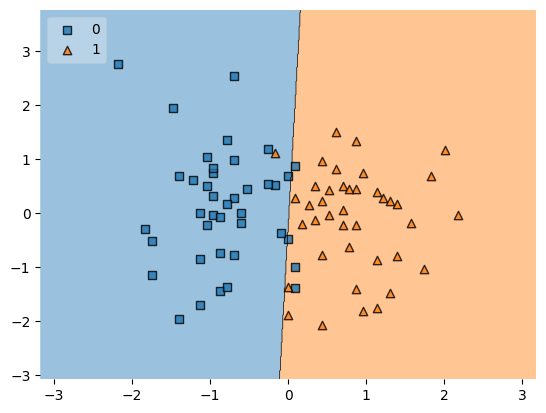

In [488]:
from mlxtend.plotting import plot_decision_regions

plot_decision_regions(X_train, Y_train.values, clf = clf, legend = 2)

### Interpretation:
  * Blue onces show they are not selected for placement
  * Orange ones are selected

# Deployment

In [489]:
import pickle

In [490]:
pickle.dump(clf,open('model.pkl','wb'))

### Saving Train and Test Datasets
Below, we reconstruct the training and testing sets as DataFrames (including both the scaled features and the target labels) and save them to CSV files.

In [491]:

# Combine X_train (scaled array) and Y_train into a single DataFrame
train_df = pd.DataFrame(X_train, columns=['scaled_cgpa', 'scaled_iq'])
train_df['placement'] = Y_train.values

# Combine X_test (scaled array) and Y_test into a single DataFrame
test_df = pd.DataFrame(X_test, columns=['scaled_cgpa', 'scaled_iq'])
test_df['placement'] = Y_test.values

# Save DataFrames to CSV files
train_df.to_csv('train.csv', index=False)
test_df.to_csv('test.csv', index=False)

print("Saved 'train.csv' and 'test.csv' successfully!")

Saved 'train.csv' and 'test.csv' successfully!


#